In [1]:
!pip install gensim -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from gensim.models import Word2Vec
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split
import time
import pickle

In [3]:
train_data = pd.read_csv('/kaggle/input/datasets/vladciuperceanu/sentiment-classification-data-256-roberta/data1/train.csv')
test_data  = pd.read_csv('/kaggle/input/datasets/vladciuperceanu/sentiment-classification-data-256-roberta/data1/test.csv')

X_train_full = train_data['sentence']
y_train_full = train_data['label']
X_test = test_data['sentence']

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

CLASSES = [0, 1, 2, 3, 4]
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')
print(y_train.value_counts().sort_index())

Train: 226800 | Val: 25200 | Test: 168000
label
0    45360
1    45360
2    45360
3    45360
4    45360
Name: count, dtype: int64


In [4]:
X_train_tokens = X_train.apply(lambda x: x.lower().split())
X_val_tokens = X_val.apply(lambda x: x.lower().split())
X_test_tokens = X_test.apply(lambda x: x.lower().split())

In [ ]:
SG = 0
VECTOR_SIZE = 300

arch_name = 'CBOW' if SG == 0 else 'SkipGram'
print(f'Training Word2Vec ({arch_name}, vector_size={VECTOR_SIZE})...')

t_start = time.time()
word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=VECTOR_SIZE,
    window=5,
    min_count=1,
    workers=4,
    sg=SG,
    seed=42
)
print(f'Word2Vec trained in {time.time() - t_start:.1f}s')
print(f'Vocabulary size: {len(word2vec_model.wv)}')
pickle.dump(word2vec_model, open(f'/kaggle/working/word2vec_{arch_name}.pkl', 'wb'))

Training Word2Vec (CBOW, vector_size=300)...
Word2Vec trained in 77.7s
Vocabulary size: 265409


In [6]:
def vectorize_text(model, text_tokens):
    vectors = [model.wv[word] for word in text_tokens if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.wv.vector_size)

t_start = time.time()
X_train_vectors = np.array([vectorize_text(word2vec_model, t) for t in X_train_tokens])
X_val_vectors   = np.array([vectorize_text(word2vec_model, t) for t in X_val_tokens])
X_test_vectors  = np.array([vectorize_text(word2vec_model, t) for t in X_test_tokens])
print(f'Vectorized in {time.time() - t_start:.1f}s')
print(f'Shapes: train={X_train_vectors.shape} val={X_val_vectors.shape} test={X_test_vectors.shape}')

Vectorized in 51.6s
Shapes: train=(226800, 300) val=(25200, 300) test=(168000, 300)


In [7]:
print('Training LinearSVC with calibration...')
t_start = time.time()
base_svm = LinearSVC(random_state=42, max_iter=2000, C=1.0)
svm = CalibratedClassifierCV(base_svm, cv=3)
svm.fit(X_train_vectors, y_train)
print(f'Trained in {time.time() - t_start:.1f}s')

Training LinearSVC with calibration...
Trained in 4804.7s


In [8]:
def evaluation_score(preds, labels):
    mae = np.mean(np.abs(np.array(preds) - np.array(labels)))
    return 1.0 - mae / 4.0

y_val_pred = svm.predict(X_val_vectors)
y_val_proba = svm.predict_proba(X_val_vectors)
y_val_binarized = label_binarize(y_val, classes=CLASSES)

val_acc = accuracy_score(y_val, y_val_pred)
val_score = evaluation_score(y_val_pred, y_val)
print(f'Val accuracy:        {val_acc:.4f}')
print(f'Val score (1-MAE/4): {val_score:.4f}')

Val accuracy:        0.5271
Val score (1-MAE/4): 0.8370



Classification report:
              precision    recall  f1-score   support

           0       0.59      0.70      0.64      5040
           1       0.43      0.40      0.41      5040
           2       0.44      0.37      0.40      5040
           3       0.48      0.41      0.45      5040
           4       0.65      0.75      0.70      5040

    accuracy                           0.53     25200
   macro avg       0.52      0.53      0.52     25200
weighted avg       0.52      0.53      0.52     25200



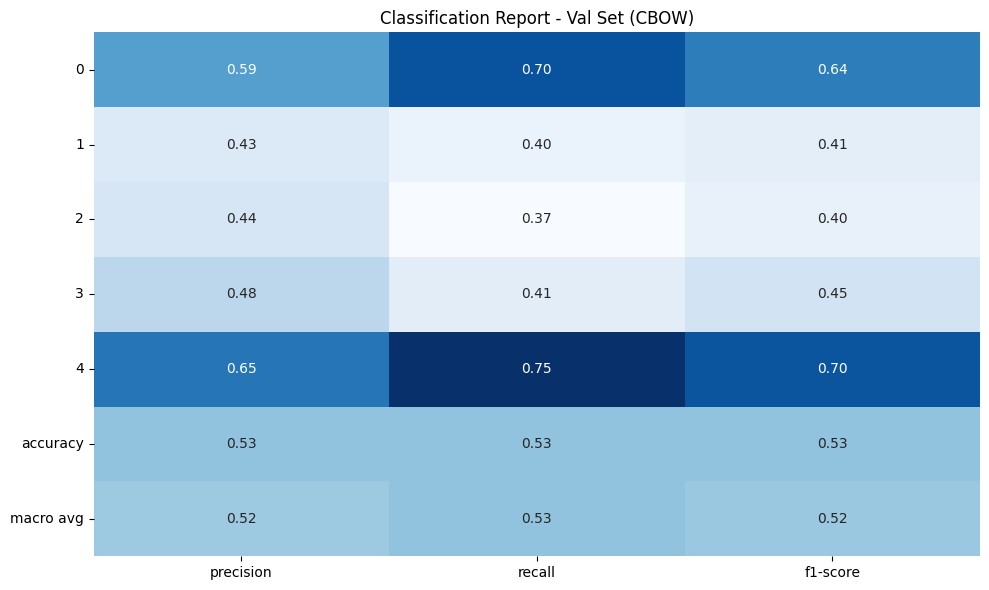

In [9]:
def plot_classification_report(y_true, y_pred, title):
    report = classification_report(y_true, y_pred, output_dict=True)
    report_df = pd.DataFrame(report).T
    plt.figure(figsize=(10, 6))
    sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', cbar=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

print('\nClassification report:')
print(classification_report(y_val, y_val_pred))
plot_classification_report(y_val, y_val_pred, f'Classification Report - Val Set ({arch_name})')

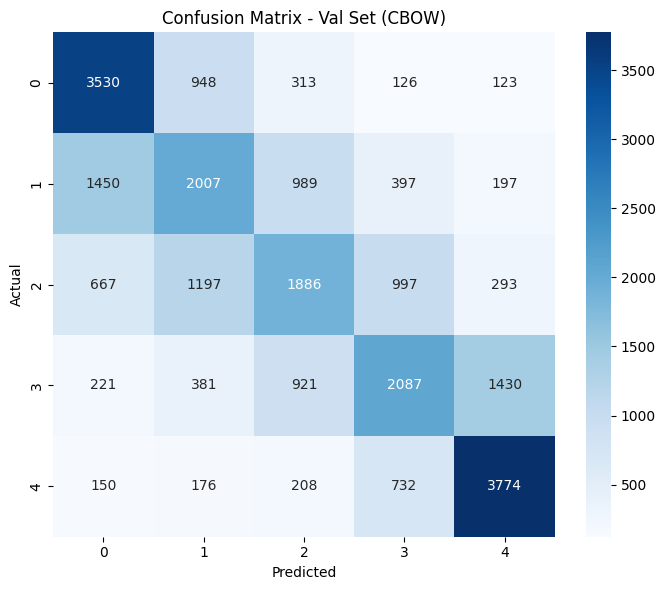

In [10]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_val, y_val_pred, f'Confusion Matrix - Val Set ({arch_name})')

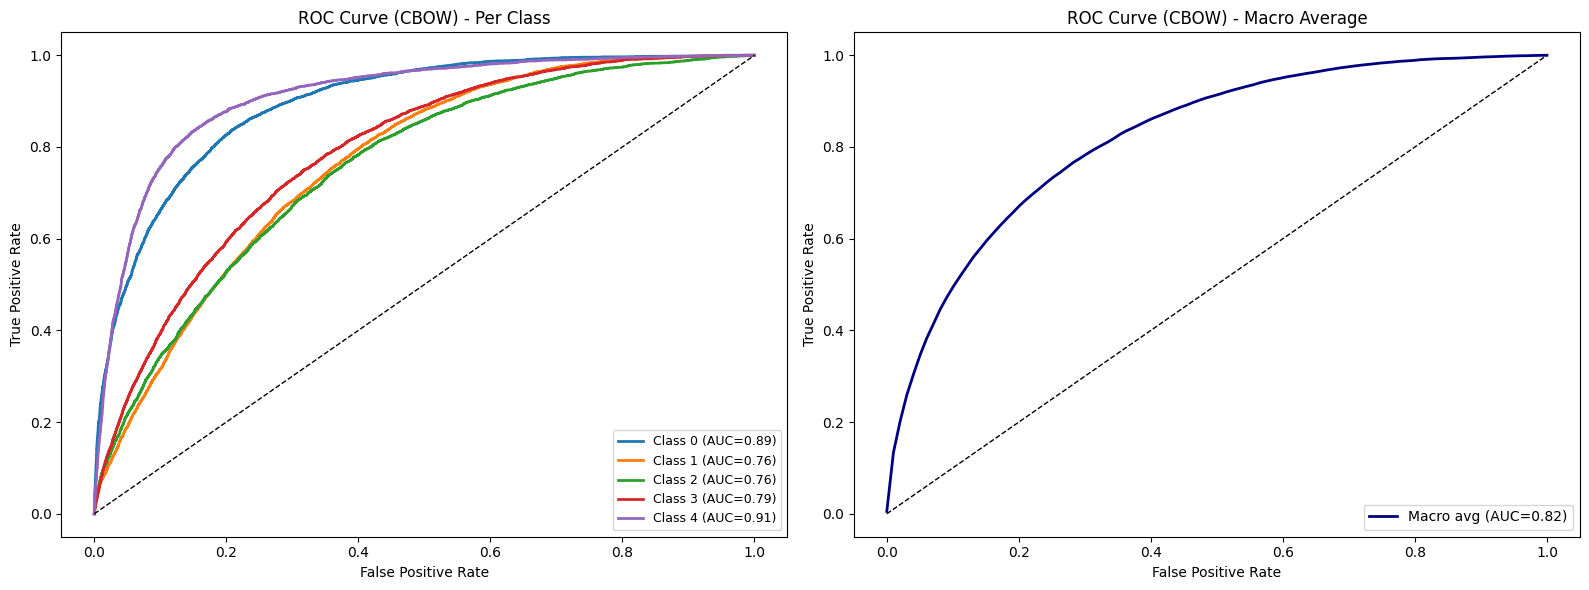

In [ ]:
def plot_roc_curve_multiclass(y_binarized, y_proba, classes, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    colors = sns.color_palette('tab10', len(classes))
    all_fpr = np.linspace(0, 1, 100)
    mean_tpr = np.zeros_like(all_fpr)

    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_binarized[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=colors[i], lw=2, label=f'Class {cls} (AUC={roc_auc:.2f})')
        mean_tpr += np.interp(all_fpr, fpr, tpr)

    axes[0].plot([0,1], [0,1], 'k--', lw=1)
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'{title} - Per Class')
    axes[0].legend(loc='lower right', fontsize=9)

    mean_tpr /= len(classes)
    macro_auc = auc(all_fpr, mean_tpr)
    axes[1].plot(all_fpr, mean_tpr, color='navy', lw=2, label=f'Macro avg (AUC={macro_auc:.2f})')
    axes[1].plot([0,1], [0,1], 'k--', lw=1)
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title(f'{title} - Macro Average')
    axes[1].legend(loc='lower right')

    plt.tight_layout()
    plt.show()

plot_roc_curve_multiclass(y_val_binarized, y_val_proba, CLASSES, f'ROC Curve ({arch_name})')

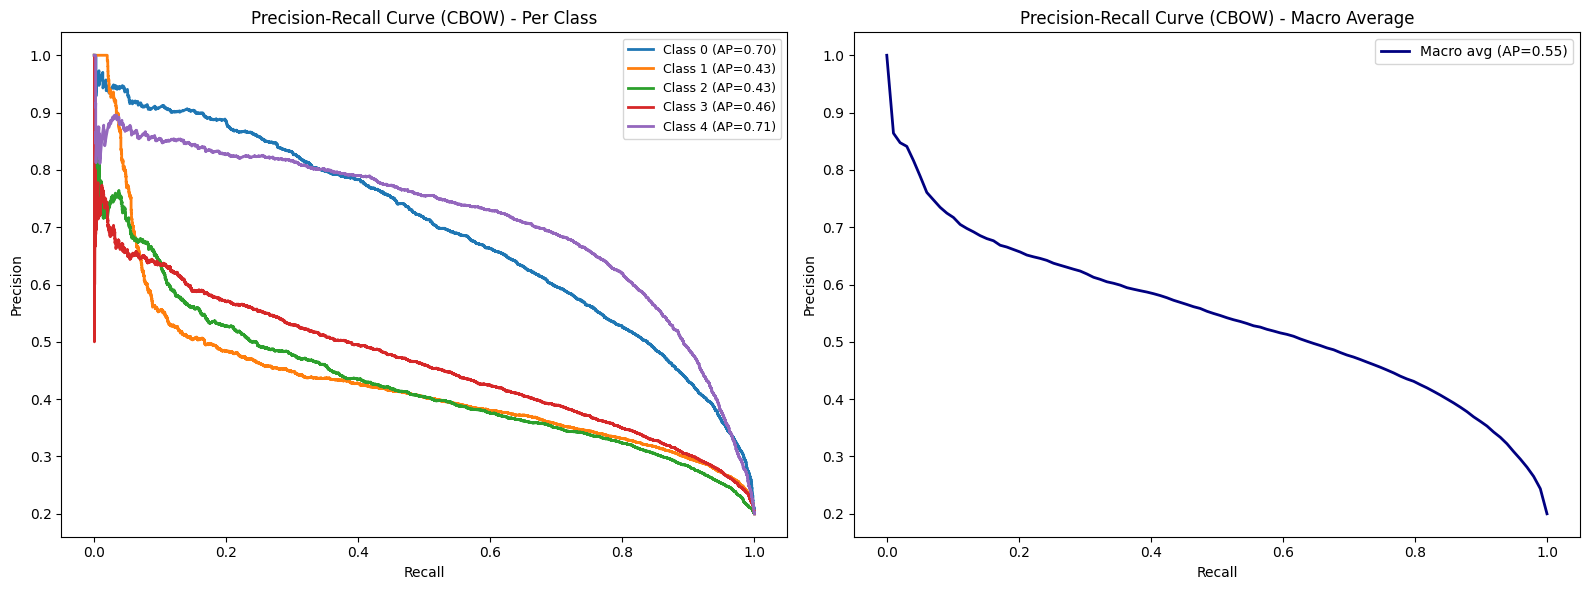

In [ ]:
def plot_pr_curve_multiclass(y_binarized, y_proba, classes, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    colors = sns.color_palette('tab10', len(classes))
    mean_recall = np.linspace(0, 1, 100)
    mean_precision = np.zeros_like(mean_recall)

    for i, cls in enumerate(classes):
        precision, recall, _ = precision_recall_curve(y_binarized[:, i], y_proba[:, i])
        ap = average_precision_score(y_binarized[:, i], y_proba[:, i])
        axes[0].plot(recall, precision, color=colors[i], lw=2, label=f'Class {cls} (AP={ap:.2f})')
        mean_precision += np.interp(mean_recall, recall[::-1], precision[::-1])

    axes[0].set_xlabel('Recall')
    axes[0].set_ylabel('Precision')
    axes[0].set_title(f'{title} - Per Class')
    axes[0].legend(loc='upper right', fontsize=9)

    mean_precision /= len(classes)
    macro_ap = np.mean([average_precision_score(y_binarized[:, i], y_proba[:, i]) for i in range(len(classes))])
    axes[1].plot(mean_recall, mean_precision, color='navy', lw=2, label=f'Macro avg (AP={macro_ap:.2f})')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title(f'{title} - Macro Average')
    axes[1].legend(loc='upper right')

    plt.tight_layout()
    plt.show()

plot_pr_curve_multiclass(y_val_binarized, y_val_proba, CLASSES, f'Precision-Recall Curve ({arch_name})')

In [13]:
y_test_pred = svm.predict(X_test_vectors)

submission_df = pd.DataFrame({
    'id': test_data['id'],
    'label': y_test_pred
})
assert len(submission_df) == len(test_data)
assert submission_df['label'].isin([0,1,2,3,4]).all()

submission_path = f'/kaggle/working/submission_svm_{arch_name}.csv'
submission_df.to_csv(submission_path, index=False)
print(f'Submission saved: {submission_path}')
print(submission_df.head(3))

Submission saved: /kaggle/working/submission_svm_CBOW.csv
   id  label
0   0      1
1   1      3
2   2      3
